# Calibration 2 — EASE sau khi khử nhân tố chung

Validation cho thấy thứ tự EASE trên $z$ phản ánh **độ nhạy với thị trường** chứ không phải lan truyền giữa các mã. Notebook này so sánh năm cách khử
nhân tố chung **trước** khi chạy EASE, bằng một thí nghiệm giả thuyết không chạy qua đúng quy trình (không tài liệu nào đã kiểm chứng sẵn cho EASE):

| Ký hiệu | Phương pháp | Công thức |
|---|---|---|
| `raw` | Gốc | $\hat\Psi$ trên $z$ |
| `loo` | Loại thị trường LOO | $e_i = z_i - \hat a_i - \hat\beta_i \bar z_{-i}$ |
| `loo_sector` | Loại thị trường + ngành LOO | hồi quy thêm $\bar z_{\text{ngành}(i)\setminus i}$ |
| `pca` | Loại $K$ nhân tố PCA (Kendall) | $e = z_s - \hat F\hat\Lambda^\top$, $\hat\Lambda$ từ ma trận $\sin(\pi\hat\tau/2)$ (Fan, Liu, Wang 2018, doi:10.1111/rssb.12265) |
| `conditional` | Có điều kiện thị trường | $\tilde\Psi_{jl} = \tfrac12 + \tfrac12\frac{\Psi_{jl}^{E} - b_{jl}}{1 - b_{jl}}$, $E$ = các phiên thị trường (trừ $j, l$) không cực trị, $b$ = mức nền trên $E$ (ý tưởng adjusted CTC, Pasche và cs. 2023, doi:10.1007/s10687-022-00456-4) |

Số quan sát đuôi $k = \lfloor n^{0{,}35}\rfloor = 14$ theo kết quả Calibration 01.

**Tiêu chí:** dưới $H_0$ (một nhân tố, không cạnh) phương pháp tốt phải cho (i) $\overline{\hat\Psi}\approx 1/2$ và (ii) thứ tự **không** tương quan với tải $\lambda$;
dưới $H_1$ (thêm cạnh thưa) phải cho SID nhỏ.

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "calibration"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import validation as V
import calibration as C
from scipy import stats
from joblib import Parallel, delayed
P = len(SYMBOLS)
OFF = ~np.eye(P, dtype=bool)
Z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")
z = Z[SYMBOLS]
n, K = len(z), CT.default_k(len(z))
NU_CAL = 0.35                     # ν chọn ở Calibration 01 (mô phỏng hiệu chỉnh + độ ổn định)
KC = CT.default_k(n, NU_CAL)
print(f"n = {n} phiên, {P} mã, k(ν=0,4) = {K}, k hiệu chỉnh (ν={NU_CAL}) = {KC}")

SECTOR = U.SECTOR
gp = pd.read_csv(ROOT / "report" / "table" / "processing" / "02_garch_params.csv", index_col=0, encoding="utf-8-sig")
NU = float(gp["nu"].mean())
lam = V.fit_one_factor(z).to_numpy()
METHODS = list(C.DECONF_METHODS)
LAB = C.DECONF_LABELS

n = 2118 phiên, 20 mã, k(ν=0,4) = 21, k hiệu chỉnh (ν=0.35) = 14


## 1. Thí nghiệm giả thuyết không và độ nhạy

**Các bước:** 60 bộ dữ liệu cỡ $n$ dưới $H_0$ (một nhân tố, tải $\hat\lambda$, không cạnh) và 60 bộ dưới $H_1$ (thêm DAG thưa, xác suất cạnh 0,08, hệ số $U(0{,}2;0{,}5)$).
Mỗi bộ, mỗi phương pháp: $\overline{\hat\Psi}$, Spearman giữa vị trí EASE và $\lambda$ (chỉ $H_0$), SID (chỉ $H_1$). Hai phương pháp ngành dùng ngành thật của 20 mã.

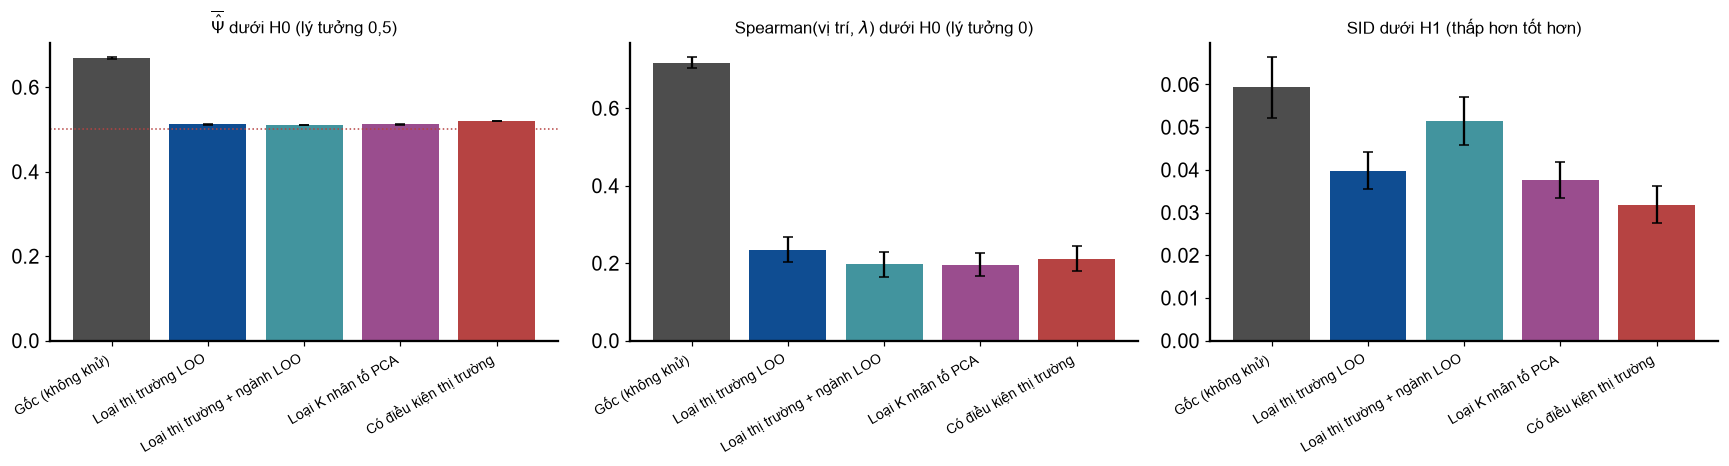

psi_TB       rho_lambda       SID      
gia_thuyet      H0    H1         H0    H1  H0    H1
phuong_phap                                        
raw          0.669 0.674      0.718 0.474 NaN 0.059
loo          0.512 0.530      0.235 0.158 NaN 0.040
loo_sector   0.511 0.529      0.198 0.131 NaN 0.051
pca          0.512 0.531      0.196 0.146 NaN 0.038
conditional  0.520 0.529      0.211 0.066 NaN 0.032

In [2]:
def one(child, h1):
    rng_ = np.random.default_rng(child)
    A_ = CT.random_dag(P, rng_, edge_prob=0.08) if h1 else np.zeros((P, P), int)
    Bc = A_ * rng_.uniform(0.2, 0.5, (P, P)) if h1 else None
    X = pd.DataFrame(V.simulate_factor_scm(n, lam, NU, B_coef=Bc, rng=rng_), columns=SYMBOLS)
    out = []
    for m in METHODS:
        M = C.method_matrix(X, m, k=KC, K=1, sector=SECTOR, corr="pearson")
        o = CT.ease(M); pos = [o.index(s) + 1 for s in SYMBOLS]
        out.append({"gia_thuyet": "H1" if h1 else "H0", "phuong_phap": m, "psi_TB": float(np.nanmean(M.values[OFF])),
                    "rho_lambda": stats.spearmanr(pos, lam)[0],
                    "SID": CT.sid(A_, CT.order_to_adjacency([SYMBOLS.index(s) for s in o])) if h1 else np.nan})
    return out

kids = np.random.SeedSequence(77).spawn(120)
rows = Parallel(n_jobs=-1)(delayed(one)(c, i >= 60) for i, c in enumerate(kids))
sim = pd.DataFrame([x for rr in rows for x in rr])
U.save_table(sim, "02_deconfounding_sim", FOLDER)
summ = sim.groupby(["phuong_phap", "gia_thuyet"]).agg(psi_TB=("psi_TB", "mean"), rho_lambda=("rho_lambda", "mean"),
                                                        SID=("SID", "mean")).unstack()
summ = summ.reindex(METHODS)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
x = np.arange(len(METHODS)); names = [LAB[m] for m in METHODS]
cm = [PAL["gray_dark"], PAL["blue_main"], PAL["teal"], PAL["violet"], PAL["red_strong"]]
for ax, (col, h, title, ref) in zip(axes, [("psi_TB", "H0", r"$\overline{\hat\Psi}$ dưới H0 (lý tưởng 0,5)", 0.5),
                                           ("rho_lambda", "H0", r"Spearman(vị trí, $\lambda$) dưới H0 (lý tưởng 0)", 0),
                                           ("SID", "H1", "SID dưới H1 (thấp hơn tốt hơn)", None)]):
    d = sim[sim.gia_thuyet == h].groupby("phuong_phap")[col].agg(["mean", "sem"]).reindex(METHODS)
    ax.bar(x, d["mean"], yerr=d["sem"], color=cm, capsize=3)
    if ref is not None:
        ax.axhline(ref, color=PAL["red_strong"], ls=":", lw=1)
    ax.set_xticks(x, names, rotation=30, ha="right", fontsize=9); ax.set_title(title, fontsize=11)
U.finalize_figure(fig, "02_deconfounding_sim", folder=FOLDER); plt.show()
summ.round(3)

### Phân tích


- **Không khử (raw)** lặp lại đúng vấn đề của Validation: dưới H0, $\overline{\hat\Psi}$ = 0,67 (thay vì 0,5) và thứ tự tương quan **ρ = 0,72** với tải $\lambda$ — thứ tự giả.
- **Mọi phương pháp khử đều đưa $\overline{\hat\Psi}$ về 0,51–0,52** và giảm ρ xuống 0,20–0,24 — giảm mạnh nhưng **không về 0**: vẫn còn một phần thứ tự theo tải.
- **Dưới H1 (có cạnh thật), phương pháp có điều kiện thị trường tốt nhất:** SID 0,032 (raw 0,059; LOO 0,040; PCA 0,038; LOO+ngành 0,051) và ρ với $\lambda$ chỉ 0,07.
  Loại thêm nhân tố ngành LOO **làm xấu đi** (0,051) — đúng như cảnh báo: nhân tố ngành từ 1–3 mã cùng ngành là biến đại diện nhiều nhiễu và tạo tương quan âm giả.

## 2. Áp dụng lên dữ liệu thật

**Tính gì:** với mỗi phương pháp: $\overline{\hat\Psi}$, $\overline{\hat\Psi}$ trong cùng ngành / khác ngành, Spearman giữa vị trí EASE và hệ số tải $\hat\lambda$,
và thứ tự EASE (5 mã đầu, 3 mã cuối).

In [3]:
sec = np.array([SECTOR[s] for s in SYMBOLS]); same = (sec[:, None] == sec[None, :]) & OFF
real, mats = [], {}
for m in METHODS:
    M = C.method_matrix(z, m, k=KC, K=1, sector=SECTOR, corr="kendall"); mats[m] = M
    o = CT.ease(M); pos = [o.index(s) + 1 for s in SYMBOLS]
    real.append({"phuong_phap": LAB[m], "psi_TB": np.nanmean(M.values[OFF]), "cung_nganh": np.nanmean(M.values[same]),
                 "khac_nganh": np.nanmean(M.values[OFF & ~same]), "rho_lambda": stats.spearmanr(pos, lam)[0],
                 "5_dau": " → ".join(o[:5]), "3_cuoi": " → ".join(o[-3:])})
real = pd.DataFrame(real).set_index("phuong_phap")
U.save_table(real, "02_real_methods", FOLDER)
pd.set_option("display.max_colwidth", 70)
real.round(3)

,psi_TB,cung_nganh,khac_nganh,rho_lambda,5_dau,3_cuoi
phuong_phap,,,,,,
Gốc (không khử),0.691,0.746,0.679,0.854,NVL → VNM → VCB → VHM → VIC,TCB → CTG → BID
Loại thị trường LOO,0.568,0.588,0.564,0.441,KDH → NVL → MSN → MWG → HPG,MBB → CTG → TCB
Loại thị trường + ngành LOO,0.555,0.607,0.543,0.116,MWG → MSN → KDH → STB → HPG,SSI → PLX → GAS
Loại K nhân tố PCA,0.566,0.578,0.564,0.035,KDH → NVL → MSN → FPT → BID,VPB → VHM → VIC
Có điều kiện thị trường,0.568,0.635,0.554,0.680,VNM → NVL → HPG → KDH → FPT,MBB → CTG → TCB


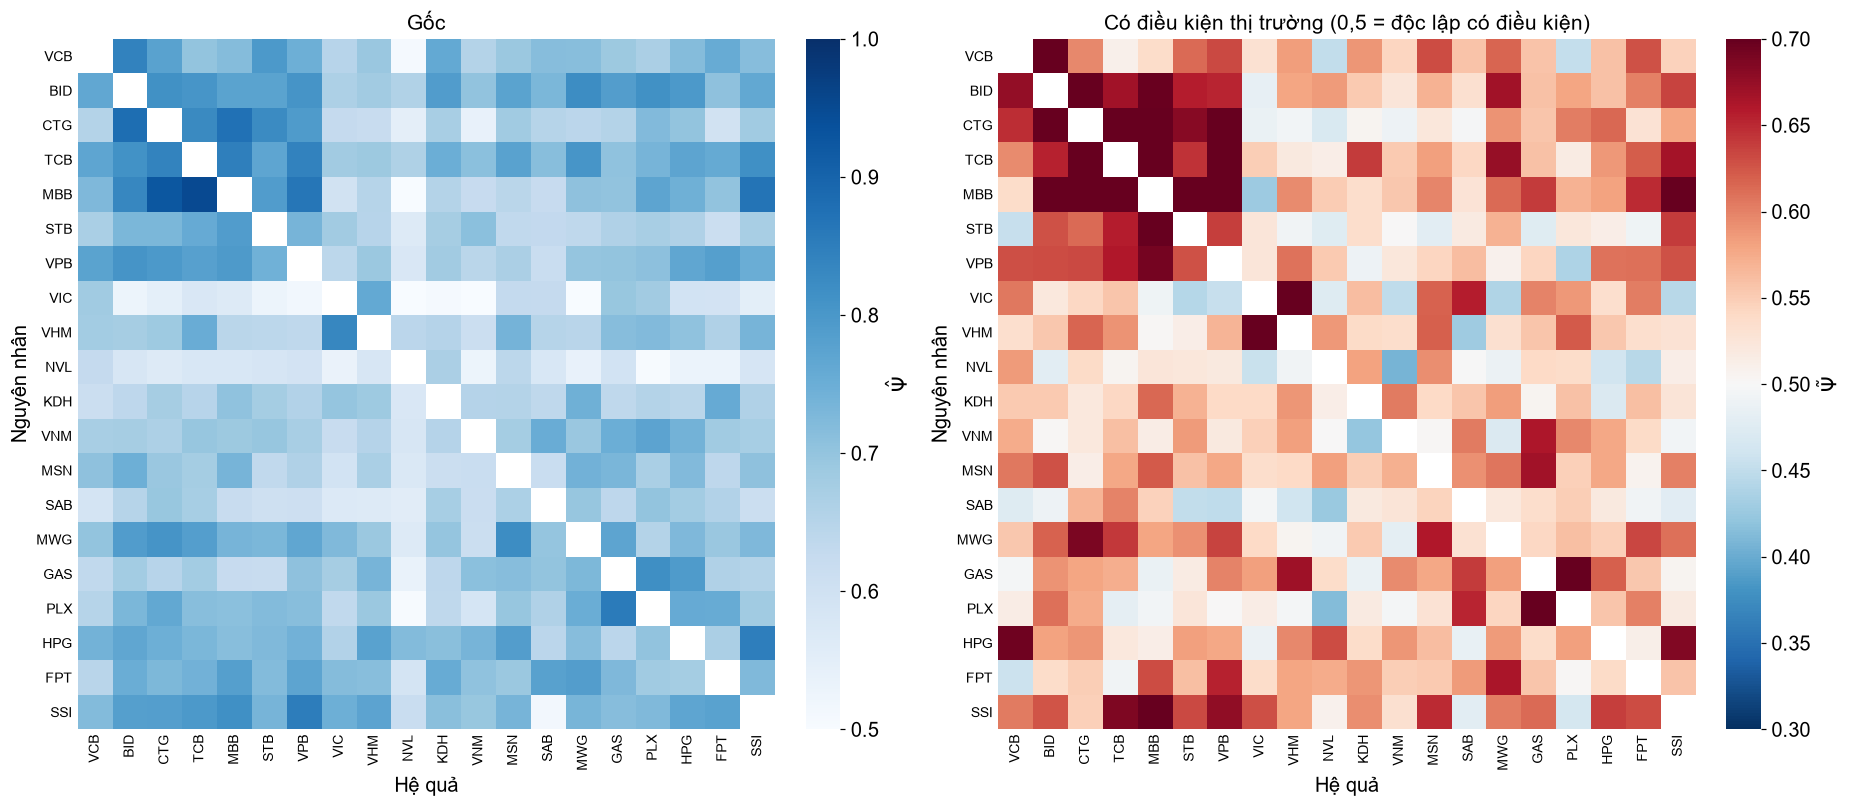

10 hệ số có điều kiện lớn nhất: {'MBB→TCB': 0.873, 'MBB→CTG': 0.819, 'VHM→VIC': 0.802, 'CTG→MBB': 0.798, 'TCB→MBB': 0.784, 'TCB→VPB': 0.761, 'CTG→BID': 0.761, 'MBB→STB': 0.759, 'MBB→SSI': 0.753, 'MBB→BID': 0.749}


In [4]:
CHOSEN = "conditional"
M = mats[CHOSEN]
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
U.make_heatmap(axes[0], mats["raw"], cmap="Blues", vmin=0.5, vmax=1, fmt=None, tick_fontsize=9, cbar_label=r"$\hat\Psi$", title="Gốc")
U.make_heatmap(axes[1], M, cmap="RdBu_r", vmin=0.3, vmax=0.7, fmt=None, tick_fontsize=9, cbar_label=r"$\tilde\Psi$",
               title="Có điều kiện thị trường (0,5 = độc lập có điều kiện)")
for ax in axes:
    ax.set_xlabel("Hệ quả"); ax.set_ylabel("Nguyên nhân")
U.finalize_figure(fig, "02_conditional_matrix", folder=FOLDER); plt.show()
st = M.stack().dropna().sort_values(ascending=False)
print("10 hệ số có điều kiện lớn nhất:", {f"{a}→{b}": round(v, 3) for (a, b), v in st.head(10).items()})

## 3. Độ tin cậy của các hệ số có điều kiện lớn nhất

**Tính gì:** bootstrap theo khối (moving block, khối $\lceil\sqrt n\rceil$ phiên, $B = 200$) của ma trận có điều kiện; khoảng 90% cho các hệ số lớn nhất và cho bất đối xứng
$D_{jl} = \tilde\Psi_{jl} - \tilde\Psi_{lj}$ của các cặp đó. Bootstrap khối giữ phụ thuộc thời gian còn sót sau lọc GARCH.

In [5]:
def block_boot(b):
    rng_ = np.random.default_rng(1000 + b); L = int(np.ceil(np.sqrt(n)))
    st_ = rng_.integers(0, n - L + 1, int(np.ceil(n / L)))
    ix = (st_[:, None] + np.arange(L)).ravel()[:n]
    return C.adjusted_tail_coef_matrix(z.iloc[ix], k=KC, seed=b)["adj"].to_numpy()

boot = np.array(Parallel(n_jobs=-1)(delayed(block_boot)(b) for b in range(200)))
top = st.head(12)
rows = []
for (a, b), v in top.items():
    i, j = SYMBOLS.index(a), SYMBOLS.index(b)
    dd = boot[:, i, j] - boot[:, j, i]
    rows.append({"cap": f"{a}→{b}", "nganh": f"{SECTOR[a]} → {SECTOR[b]}", "psi_dk": v,
                 "q05": np.nanquantile(boot[:, i, j], 0.05), "q95": np.nanquantile(boot[:, i, j], 0.95),
                 "D": M.loc[a, b] - M.loc[b, a], "D_q05": np.nanquantile(dd, 0.05), "D_q95": np.nanquantile(dd, 0.95)})
topt = pd.DataFrame(rows).set_index("cap")
topt["vuot_0.5"] = topt.q05 > 0.5; topt["co_chieu"] = (topt.D_q05 > 0) | (topt.D_q95 < 0)
U.save_table(topt, "02_top_conditional", FOLDER)
topt.round(3)

,nganh,psi_dk,q05,q95,D,D_q05,D_q95,vuot_0.5,co_chieu
cap,,,,,,,,,
MBB→TCB,Ngân hàng → Ngân hàng,0.873,0.791,0.913,0.089,0.002,0.151,True,True
MBB→CTG,Ngân hàng → Ngân hàng,0.819,0.765,0.905,0.022,-0.068,0.110,True,False
VHM→VIC,Bất động sản → Bất động sản,0.802,0.720,0.894,0.061,-0.025,0.149,True,False
CTG→MBB,Ngân hàng → Ngân hàng,0.798,0.738,0.889,-0.022,-0.110,0.068,True,False
TCB→MBB,Ngân hàng → Ngân hàng,0.784,0.723,0.850,-0.089,-0.151,-0.002,True,True
TCB→VPB,Ngân hàng → Ngân hàng,0.761,0.662,0.798,0.102,-0.018,0.187,True,False
CTG→BID,Ngân hàng → Ngân hàng,0.761,0.674,0.835,0.047,-0.055,0.153,True,False
MBB→STB,Ngân hàng → Ngân hàng,0.759,0.620,0.822,0.046,-0.090,0.104,True,False
MBB→SSI,Ngân hàng → Chứng khoán,0.753,0.633,0.807,0.024,-0.114,0.095,True,False


### Phân tích


- Trên dữ liệu thật, khử nhân tố đưa $\overline{\hat\Psi}$ từ 0,69 về 0,56–0,57. Tương quan giữa thứ tự và tải: raw 0,85 → LOO 0,44 → LOO+ngành 0,12 → **PCA 0,04** →
  có điều kiện 0,68. Phương pháp có điều kiện vẫn giữ ρ = 0,68, cao hơn nhiều mức 0,21 mà nó cho dưới H0 — dấu hiệu dữ liệu thật có cấu trúc **ngoài** một nhân tố:
  ngân hàng vừa tải cao vừa phụ thuộc đuôi mạnh với nhau.
- **Phụ thuộc đuôi còn lại tập trung trong ngân hàng và Vingroup:** cùng ngành 0,635 so với khác ngành 0,554 (phương pháp có điều kiện). 10 hệ số lớn nhất gồm MBB→TCB 0,87, MBB→CTG 0,82,
  VHM→VIC 0,80, CTG→MBB 0,80, TCB→MBB 0,78, TCB→VPB 0,76, CTG→BID 0,76 … — đều trong một ngành (riêng MBB→SSI là ngân hàng → chứng khoán).
- **Chiều:** trong 12 hệ số lớn nhất, chỉ cặp **MBB–TCB** có bất đối xứng với khoảng bootstrap khối 90% không chứa 0 ($D$ = +0,09, [0,002; 0,151]) — sát ngưỡng, và trong
  một kiểm định không hiệu chỉnh đa so sánh; coi là gợi ý (MBB → TCB), chưa phải bằng chứng.
- Thứ tự EASE có điều kiện: VNM → NVL → HPG → KDH → FPT … → MBB → CTG → TCB. Ngân hàng vẫn ở cuối, nhưng nay vì **phụ thuộc đuôi trong ngành**, không còn chỉ vì tải thị trường.

## 4. Kết luận


1. **Khử nhân tố là bắt buộc** trước EASE trên dữ liệu cổ phiếu: không khử, thứ tự gần như là thứ tự hệ số tải (ρ = 0,72 dưới H0, 0,85 trên dữ liệu thật).
2. **Hệ số có điều kiện thị trường** (ý tưởng adjusted CTC) là phương pháp tốt nhất trong mô phỏng có cạnh thật (SID 0,032); PCA một nhân tố khử thứ tự theo tải tốt nhất trên dữ liệu thật.
   Loại nhân tố ngành bằng LOO với ngành nhỏ phản tác dụng.
3. Sau khi khử, phụ thuộc đuôi còn lại là **trong ngành** (ngân hàng, Vingroup); chưa có chiều nhân quả giữa hai mã nào đạt độ tin cậy cao.